## Given,problem statement and questions
- Use a voice recording wav file of about 10 seconds with minimal background noise
- Take the STFT of the signal, separately plot the magnitude (MG) and phase (PH) of the signal
- Using only the magnitude (consider zero phase) do inverse FT, call it sig1.
- What is the difference between the original and sig1. Give reasoning and analysis.
- Create an array (PH1) with size identical to that of PH and consider MG & PH1 to do inverse FT, call it sig2. 
- Is it possible to get real valued sig2?
- What is the difference between the original and sig2. Give reasoning and analysis
- What is the difference between sig1 and sig2. Give reasoning and analysis
- Is there a pattern in PH1 that ensures real valued sig2? 
- How many such patterns are possible? 


- Create unintelligible version (using odd yet random phase) of every speech signal and ask them to recover the original back.
- Add white, machinegun, babble noises from  NoiseX dataset from (https://github.com/speechdnn/Noises/tree/masterNoiseX-92) to the original wav file at -2dB, 0dB, 2dB, 5dB and 10dB SNR
- Calculate STOI scores in each scenario
- Repeat the above operations (2 to 5) for each noise
- Apply a Band Pass Filter to the signal and compare the STOI score with each noise. Comment on the filter design decisions and STOI scores

In [26]:
#imports
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd

In [27]:
ipd.Audio(f'voice_rec.wav')

In [28]:
y,sr=librosa.load(f'voice_rec.wav')
print('y:', y, '\n')
print('y shape:', np.shape(y), '\n')
print('sample Rate (KHz):', sr, '\n')

y: [ 2.2007634e-05 -2.7910966e-05  3.1030668e-05 ... -5.3287193e-04
 -6.8299426e-04 -4.1674965e-04] 

y shape: (229705,) 

sample Rate (KHz): 22050 



Assumption->STFT paramas
window: hann
n_fft=512
hop_length=128

In [80]:
n_fft = 512
hop_len = 128
wind = "hann"

D = librosa.stft(y,n_fft=n_fft,hop_length=hop_len,window=wind)
MG = np.abs(D)
PH = np.angle(D)

In [81]:
MG_db = librosa.amplitude_to_db(MG,ref=np.max)
times = librosa.times_like(D,sr=sr,hop_length=hop_len)
frq = librosa.fft_frequencies(sr=sr,n_fft=n_fft)

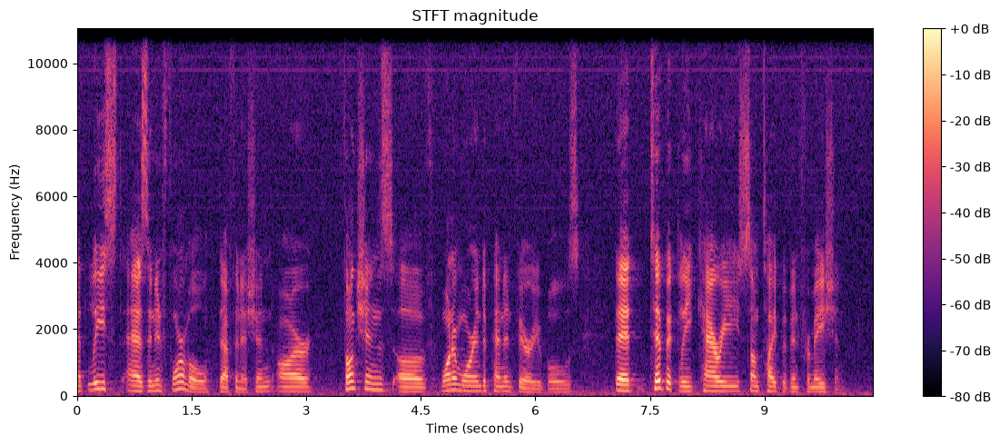

In [82]:
plt.figure(figsize=(12,5))
librosa.display.specshow(
    MG_db,
    sr=sr,
    hop_length=hop_len,
    x_axis="time",
    y_axis="hz",
    cmap="magma"
)
plt.colorbar(format="%+2.0f dB")
plt.title("STFT magnitude")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

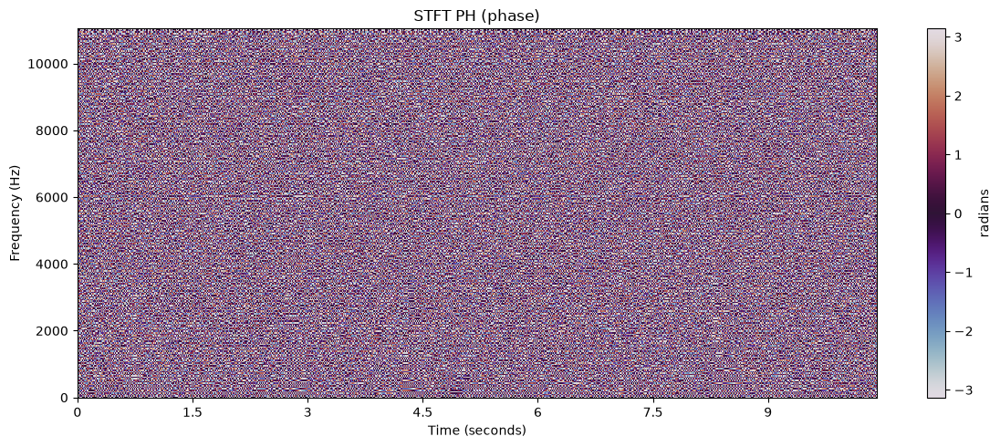

In [83]:
plt.figure(figsize=(12,5))
librosa.display.specshow(
    PH,
    sr=sr,
    hop_length=hop_len,
    x_axis="time",
    y_axis="hz",
    cmap="twilight"
)
plt.colorbar(label="radians")
plt.title("STFT PH (phase)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

In [85]:
D_MG = MG*np.exp(1j*0)
sig1 = librosa.istft(D_MG,hop_length=hop_len,win_length=n_fft,window="hann",length=len(y))


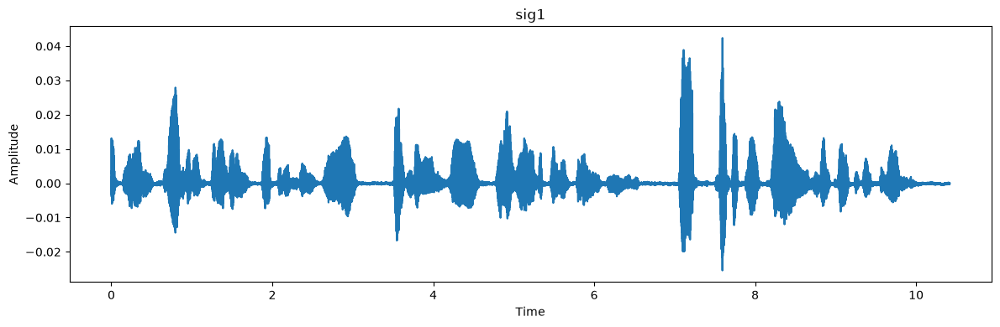

In [86]:
t_sig1 = np.arange(len(sig1))/sr
plt.figure(figsize=(12, 4))
plt.plot(t_sig1, sig1)
plt.title("sig1")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

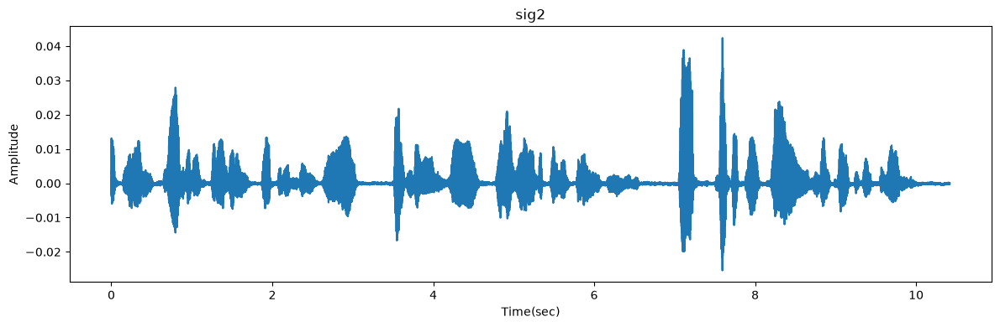

In [87]:
PH1 = np.zeros_like(PH)

D_sig2 = MG*np.exp(1j*PH1)

sig2 = librosa.istft(D_sig2,hop_length=hop_len,win_length=n_fft,window="hann",length=len(y))
t_sig2=np.arange(len(sig2))/sr

plt.figure(figsize=(12, 4))
plt.plot(t_sig2, sig2)
plt.title("sig2")
plt.xlabel("Time(sec)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()


In [38]:
ipd.Audio(f'babble.wav')

In [39]:
ipd.Audio(f'machinegun.wav')

In [40]:
ipd.Audio(f'white.wav')

In [ ]:
def randnoise(shape,rng):
    ph=rng.uniform(low=-np.pi,high=np.pi,size=shape)
    ph[0,:]=0.0
    ph[-1,:]=0.0
    return ph

rng = np.random.default_rng(0)
ph = randnoise(PH.shape,rng)
D_scram =  MG * np.exp(1j * ph)
sig_scram = librosa.istft(D_scram, hop_length=hop_len, win_length=n_fft, window="hann", length=len(y))

    

In [ ]:
from IPython.display import Audio, display
sig_scram_normalized = sig_scram / (np.max(np.abs(sig_scram)) + 1e-12)

display(Audio(
    data=sig_scram_normalized,
    rate=sr
))

In [89]:
import pystoi.stoi as stoi
def recover(x, sr, nfft, hop, n_iter=300, momentum=0.99, seed=0, mag=None):
    if mag is None:
        mag = np.abs(librosa.stft(x, n_fft=nfft, hop_length=hop,win_length=nfft, window="hann"))
    rec = librosa.griffinlim(mag, n_iter=n_iter, momentum=momentum,hop_length=hop, win_length=nfft, window="hann",length=len(x), rng=seed)
    return rec

sig_rec = recover(sig_scram, sr, n_fft, hop_len)
sig_rec_oracle = recover(sig_scram, sr, n_fft, hop_len, mag=MG)
print("STOI scrambled        :", stoi(y, sig_scram, sr))
print("STOI recovered        :", stoi(y, sig_rec, sr))
print("STOI recovered oracle :", stoi(y, sig_rec_oracle, sr))

STOI scrambled        : 0.8607286214091554
STOI recovered        : 0.8606968074751862
STOI recovered oracle : 0.9985975227711728


In [64]:
from IPython.display import Audio, display
sig_rec_normalized = sig_rec / (np.max(np.abs(sig_rec)) + 1e-12)

display(Audio(
    data=sig_rec_normalized,
    rate=sr
))

In [66]:
from IPython.display import Audio, display
sig_or_normalized = sig_rec_oracle / (np.max(np.abs(sig_rec_oracle)) + 1e-12)

display(Audio(
    data=sig_or_normalized,
    rate=sr
))

In [72]:
snr_db=[-2,0,2,5,10]
files = {"babble": "babble.wav", "machinegun": "machinegun.wav", "white": "white.wav"}
noisy_signals = {}
def addnoise(clean, noise, snr_db):
    if len(noise) < len(clean):
        noise = np.tile(noise, int(np.ceil(len(clean) / len(noise))))
    noise = noise[:len(clean)]
    clean_power = np.mean(clean**2)
    noise_power = np.mean(noise**2)
    scale = np.sqrt(
        clean_power / (noise_power * 10 ** (snr_db / 10))
    )
    return clean + scale * noise

res = []
for noise_name, noise_file in files.items():
    noise,noise_sr = librosa.load(noise_file,sr=None,mono=True)
    if noise_sr != sr:
        noise = librosa.resample(noise, orig_sr=noise_sr, target_sr=sr)
    for snr in snr_db:
        noisy = addnoise(y, noise, snr)
        noisy_signals[(noise_name, snr)] = noisy
        score = stoi(y, noisy, sr,extended=False)
        res.append({"noise": noise_name, "snr_db": snr, "STOI": score})
        print(f"Noise: {noise_name}, SNR: {snr} dB, STOI: {score:.4f}")


Noise: babble, SNR: -2 dB, STOI: 0.5793
Noise: babble, SNR: 0 dB, STOI: 0.6268
Noise: babble, SNR: 2 dB, STOI: 0.6738
Noise: babble, SNR: 5 dB, STOI: 0.7412
Noise: babble, SNR: 10 dB, STOI: 0.8368
Noise: machinegun, SNR: -2 dB, STOI: 0.7607
Noise: machinegun, SNR: 0 dB, STOI: 0.7892
Noise: machinegun, SNR: 2 dB, STOI: 0.8162
Noise: machinegun, SNR: 5 dB, STOI: 0.8539
Noise: machinegun, SNR: 10 dB, STOI: 0.9085
Noise: white, SNR: -2 dB, STOI: 0.6896
Noise: white, SNR: 0 dB, STOI: 0.7324
Noise: white, SNR: 2 dB, STOI: 0.7725
Noise: white, SNR: 5 dB, STOI: 0.8259
Noise: white, SNR: 10 dB, STOI: 0.8931


In [78]:
noisy_test = noisy_signals[("machinegun", -2)]

display(Audio(noisy_test,rate=sr))

In [79]:
import soundfile as sf
import os
for (noise_name, snr), noisy in noisy_signals.items():
    filename = f"{noise_name}_{snr}dB.wav"
    filepath = os.path.join("outputs", filename)
    sf.write(filepath, noisy, sr)
    print(f"Saved {filepath}")

Saved outputs\babble_-2dB.wav
Saved outputs\babble_0dB.wav
Saved outputs\babble_2dB.wav
Saved outputs\babble_5dB.wav
Saved outputs\babble_10dB.wav
Saved outputs\machinegun_-2dB.wav
Saved outputs\machinegun_0dB.wav
Saved outputs\machinegun_2dB.wav
Saved outputs\machinegun_5dB.wav
Saved outputs\machinegun_10dB.wav
Saved outputs\white_-2dB.wav
Saved outputs\white_0dB.wav
Saved outputs\white_2dB.wav
Saved outputs\white_5dB.wav
Saved outputs\white_10dB.wav


In [90]:
# main fnc for 2 to 5
def fnc_2to5(voice_file):
    y,sr=librosa.load(voice_file)
    print('y:', y, '\n')
    print('y shape:', np.shape(y), '\n')
    print('sample Rate (KHz):', sr, '\n')

    n_fft = 512
    hop_len = 128
    wind = "hann"

    D = librosa.stft(y,n_fft=n_fft,hop_length=hop_len,window=wind)
    MG = np.abs(D)
    PH = np.angle(D)

    MG_db = librosa.amplitude_to_db(MG,ref=np.max)
    times = librosa.times_like(D,sr=sr,hop_length=hop_len)
    frq = librosa.fft_frequencies(sr=sr,n_fft=n_fft)
    plt.figure(figsize=(12,5))
    librosa.display.specshow(
        MG_db,
        sr=sr,
        hop_length=hop_len,
        x_axis="time",
        y_axis="hz",
        cmap="magma"
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title("STFT magnitude")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(12,5))
    librosa.display.specshow(
        PH,
        sr=sr,
        hop_length=hop_len,
        x_axis="time",
        y_axis="hz",
        cmap="twilight"
    )
    plt.colorbar(label="radians")
    plt.title("STFT PH (phase)")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()
    


Processing outputs\babble_-2dB.wav...
y: [-0.00814819 -0.01040649 -0.01101685 ... -0.03601074 -0.03564453
 -0.03442383] 

y shape: (229705,) 

sample Rate (KHz): 22050 



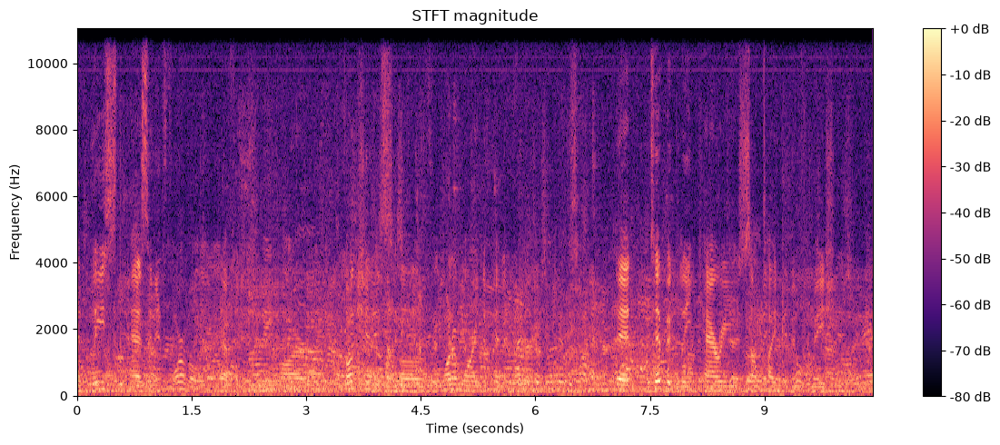

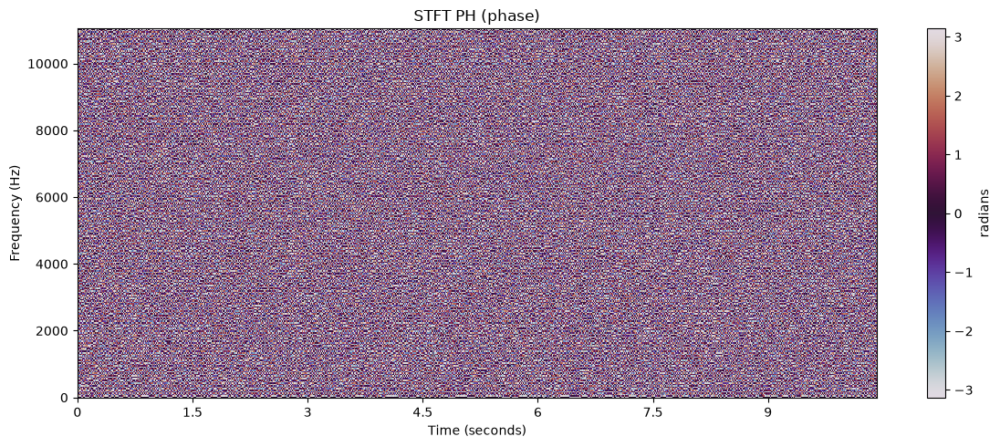

Processing outputs\babble_0dB.wav...
y: [-0.00646973 -0.00827026 -0.00875854 ... -0.02871704 -0.0284729
 -0.0274353 ] 

y shape: (229705,) 

sample Rate (KHz): 22050 



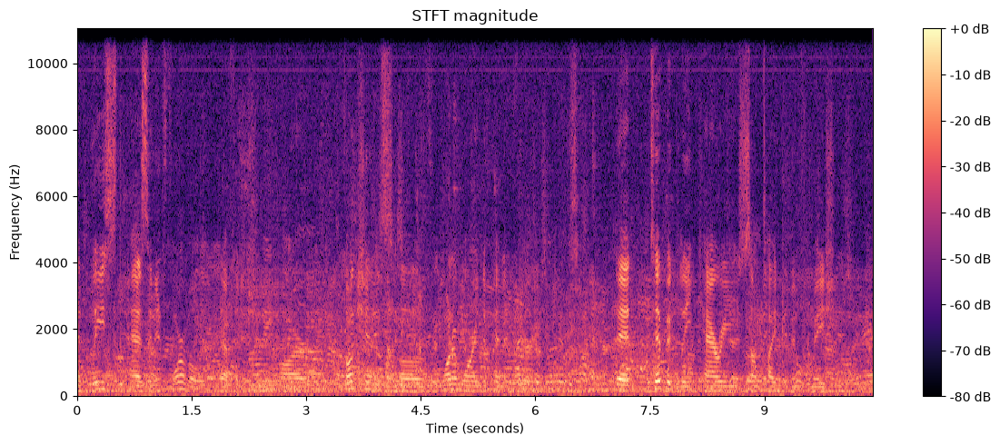

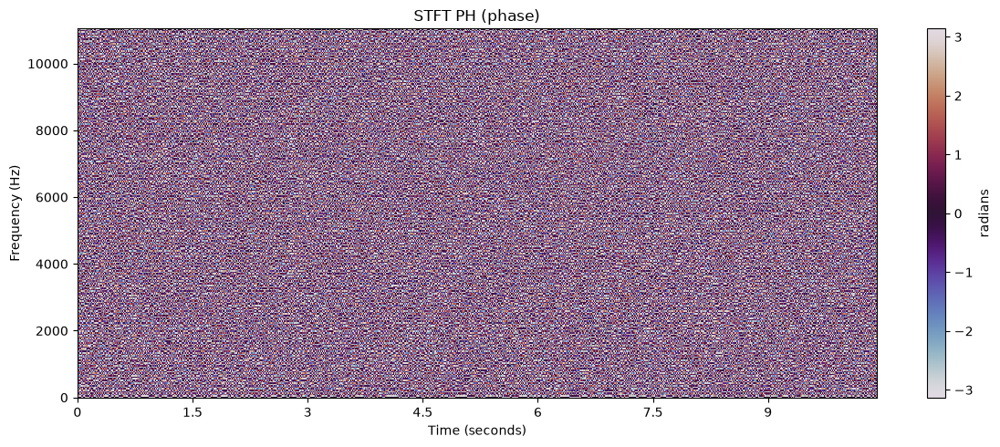

Processing outputs\babble_10dB.wav...
y: [-0.00204468 -0.00265503 -0.00274658 ... -0.00946045 -0.00949097
 -0.00897217] 

y shape: (229705,) 

sample Rate (KHz): 22050 



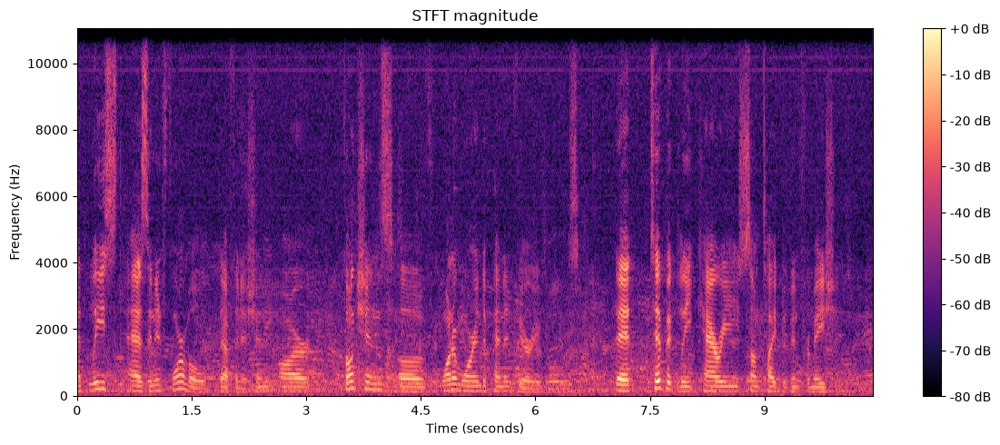

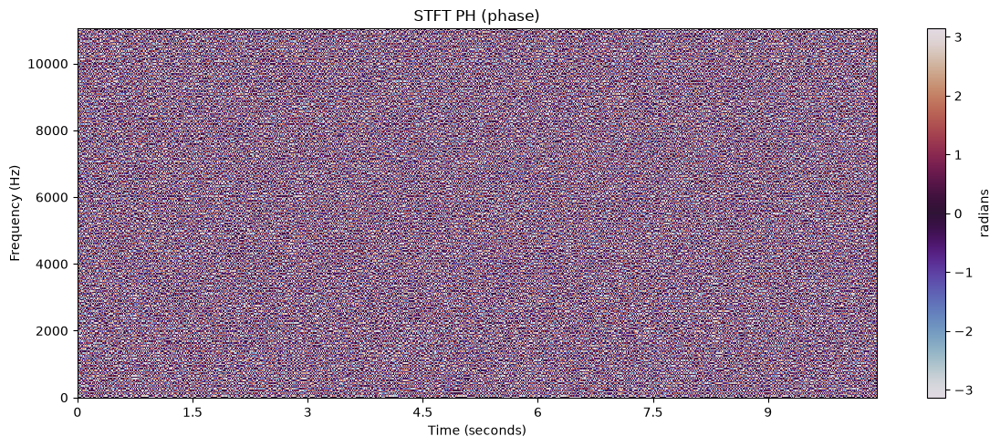

Processing outputs\babble_2dB.wav...
y: [-0.00515747 -0.0065918  -0.00695801 ... -0.0229187  -0.02276611
 -0.0218811 ] 

y shape: (229705,) 

sample Rate (KHz): 22050 



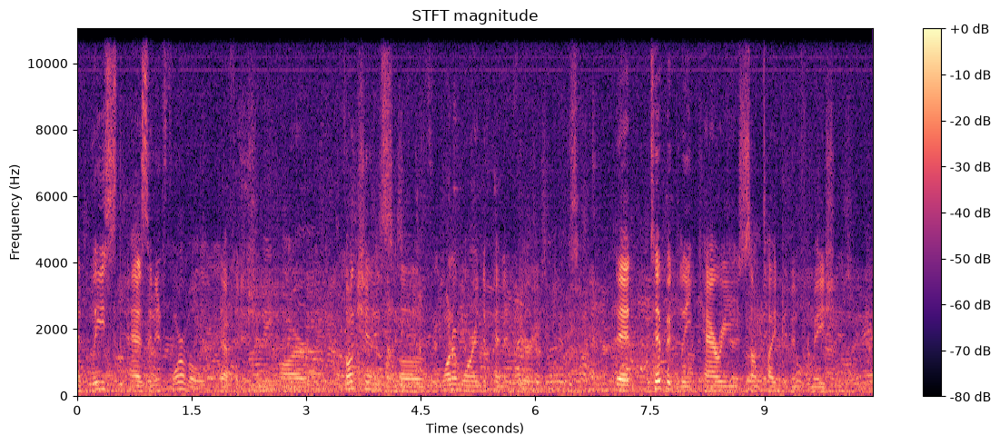

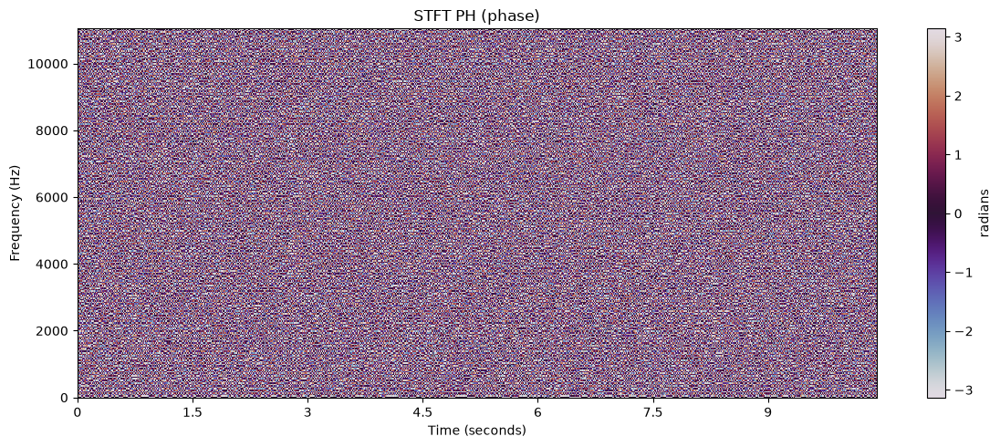

Processing outputs\babble_5dB.wav...
y: [-0.00363159 -0.00466919 -0.00491333 ... -0.01638794 -0.01629639
 -0.015625  ] 

y shape: (229705,) 

sample Rate (KHz): 22050 



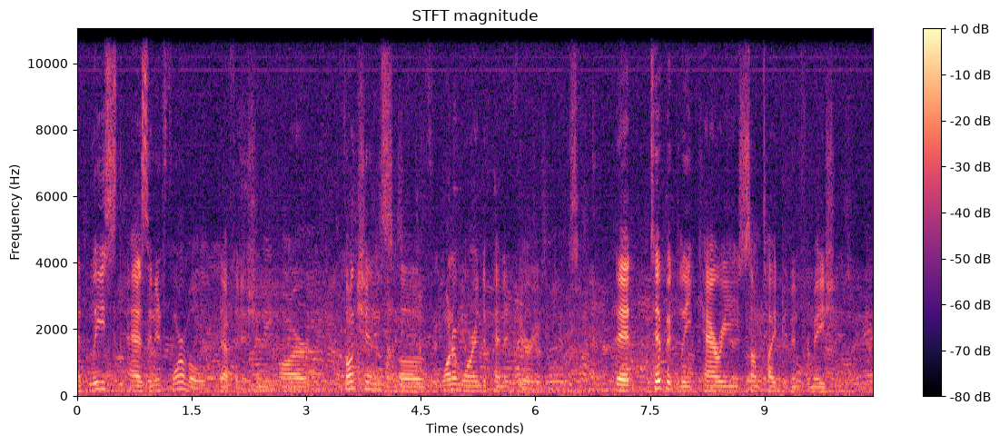

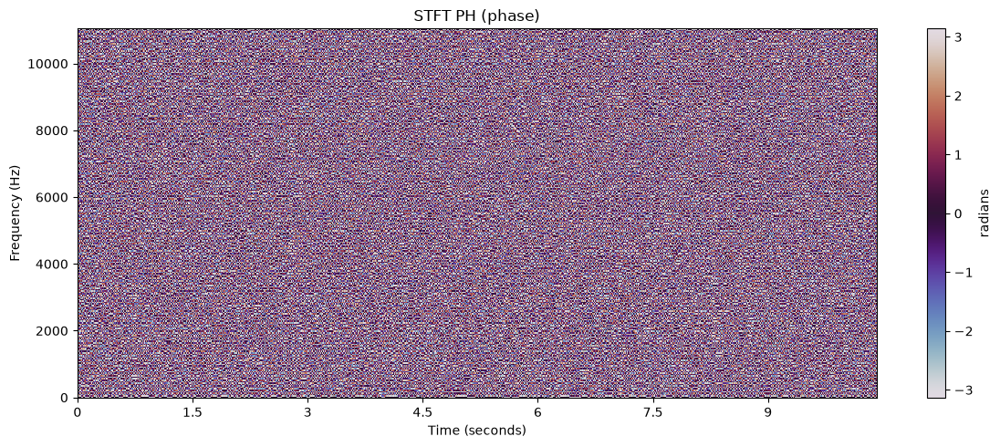

Processing outputs\machinegun_-2dB.wav...
y: [ 0.00601196  0.00619507  0.00384521 ... -0.04824829 -0.04696655
 -0.04483032] 

y shape: (229705,) 

sample Rate (KHz): 22050 



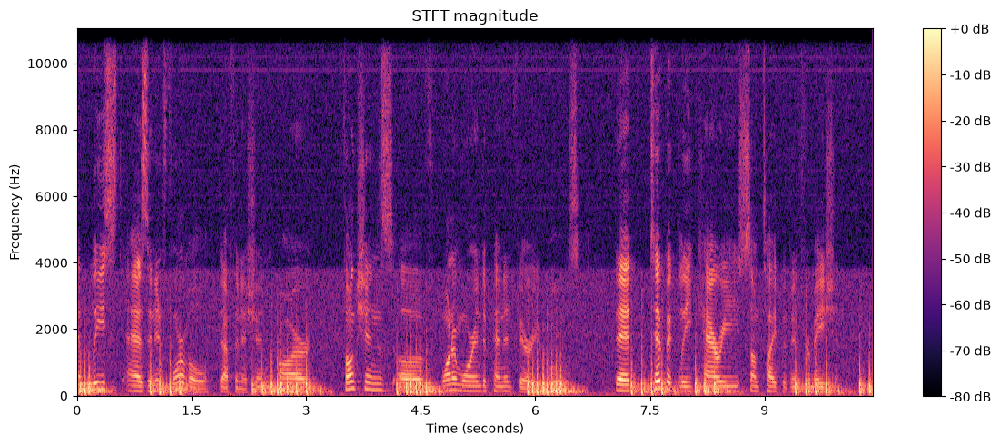

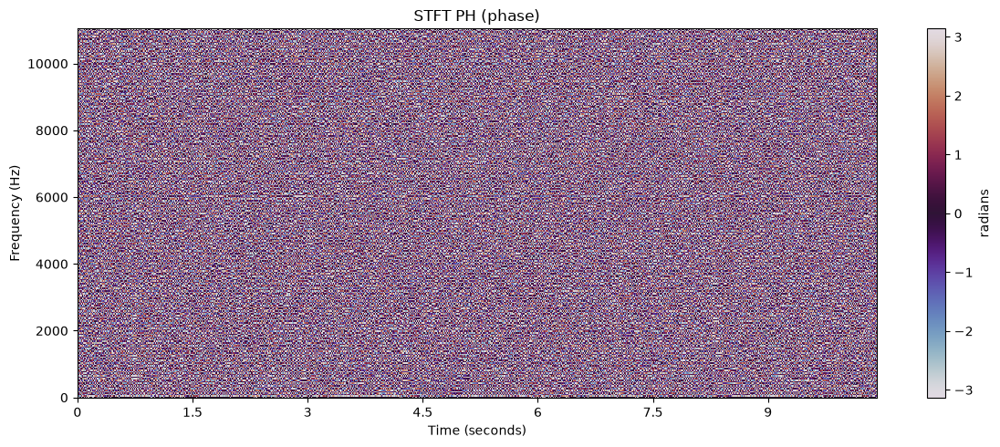

Processing outputs\machinegun_0dB.wav...
y: [ 0.00476074  0.00491333  0.00305176 ... -0.03842163 -0.03744507
 -0.03570557] 

y shape: (229705,) 

sample Rate (KHz): 22050 



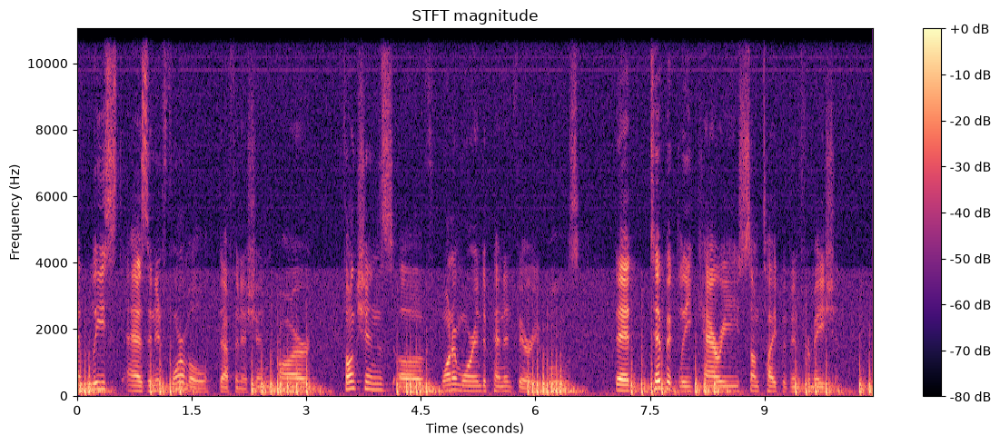

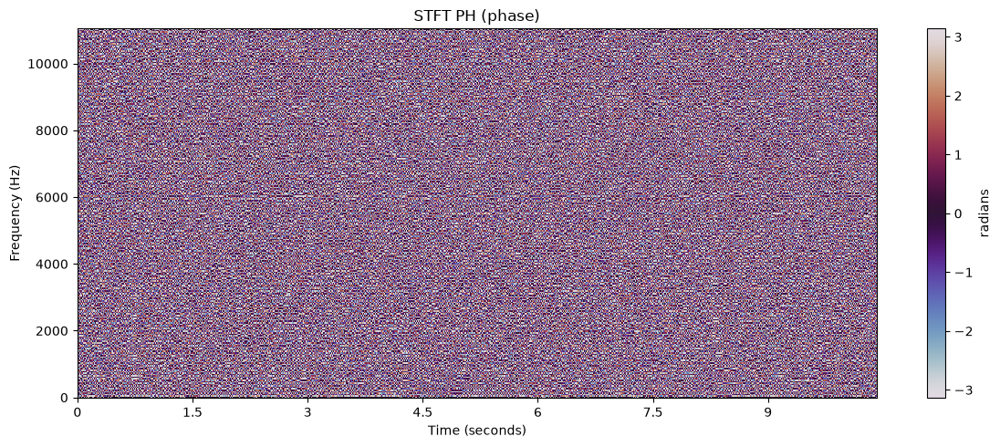

Processing outputs\machinegun_10dB.wav...
y: [ 0.00152588  0.00152588  0.00097656 ... -0.01254272 -0.0123291
 -0.01159668] 

y shape: (229705,) 

sample Rate (KHz): 22050 



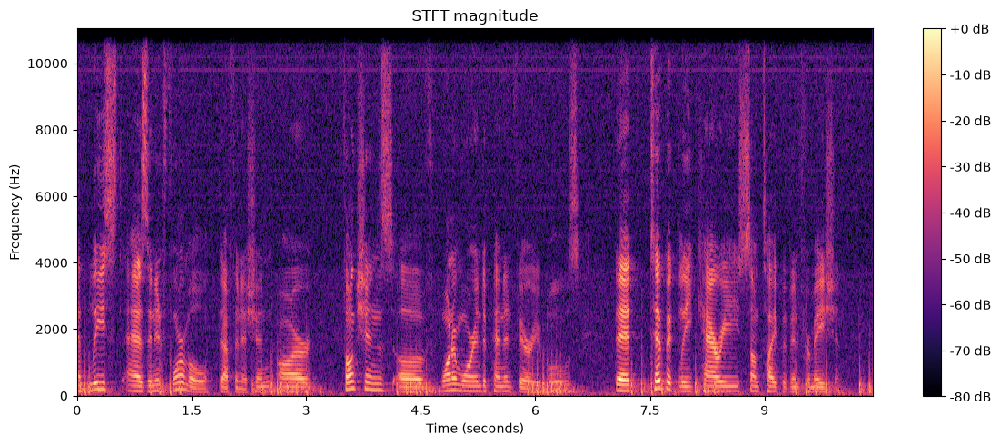

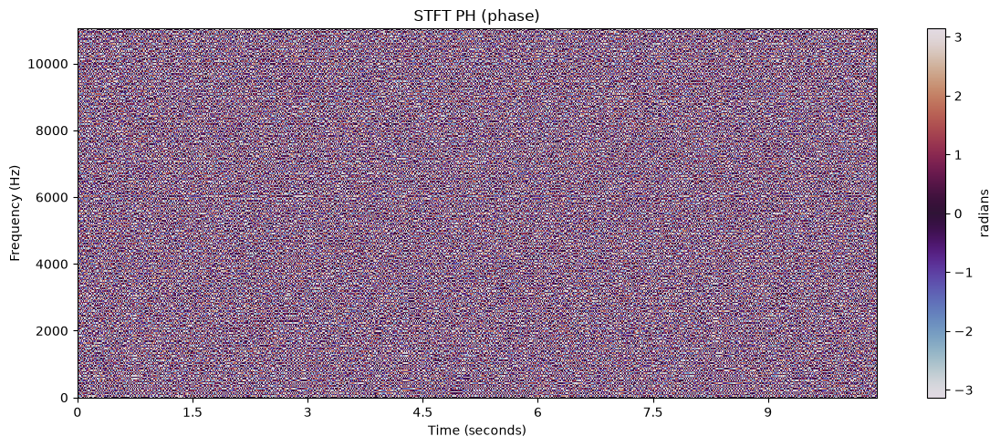

Processing outputs\machinegun_2dB.wav...
y: [ 0.00378418  0.00387573  0.00244141 ... -0.03063965 -0.02990723
 -0.02844238] 

y shape: (229705,) 

sample Rate (KHz): 22050 



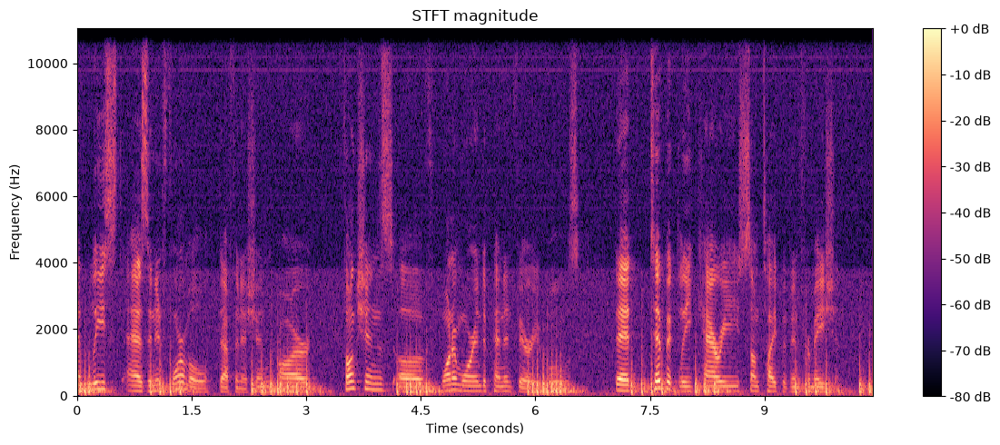

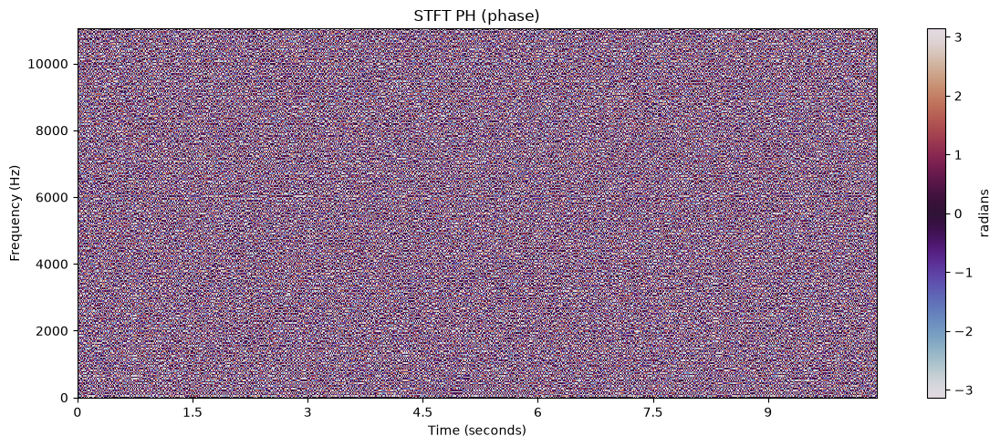

Processing outputs\machinegun_5dB.wav...
y: [ 0.00268555  0.00274658  0.0017395  ... -0.02185059 -0.0213623
 -0.02026367] 

y shape: (229705,) 

sample Rate (KHz): 22050 



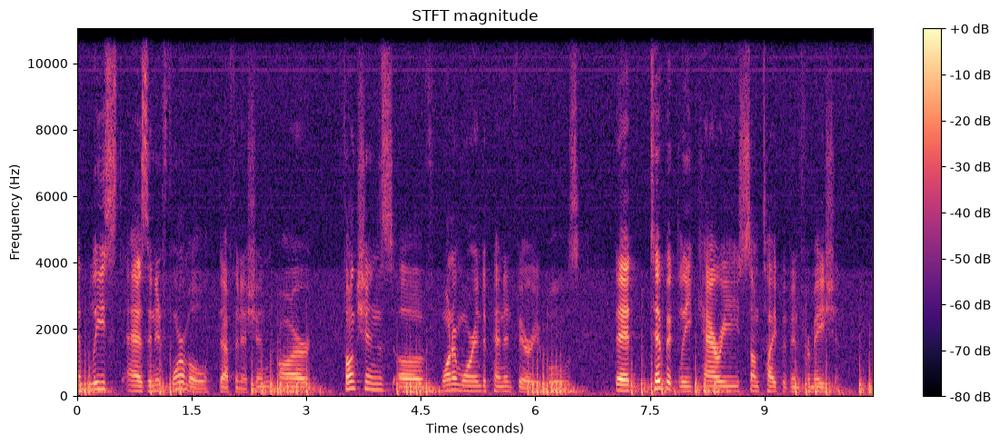

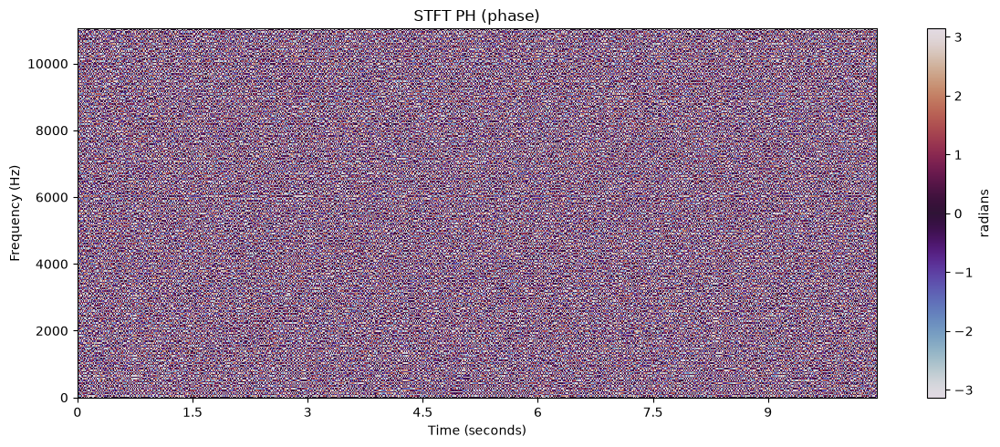

Processing outputs\white_-2dB.wav...
y: [-0.01901245 -0.00820923  0.01242065 ... -0.01602173  0.02835083
  0.02514648] 

y shape: (229705,) 

sample Rate (KHz): 22050 



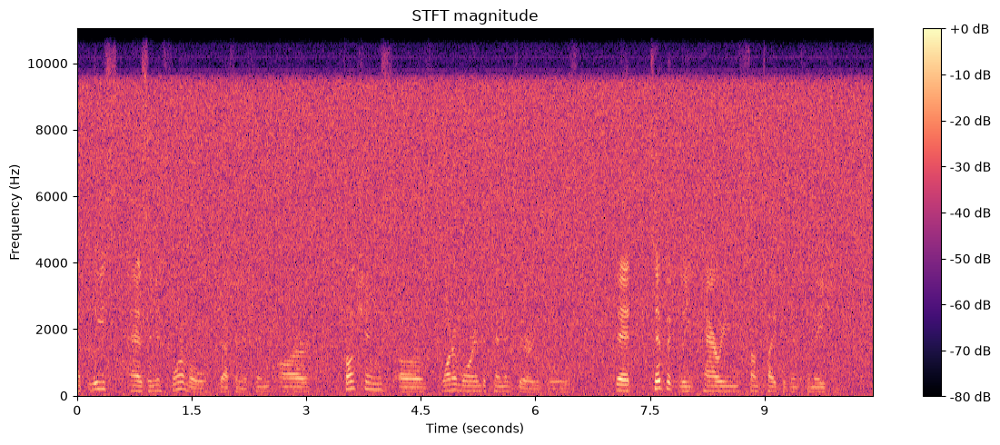

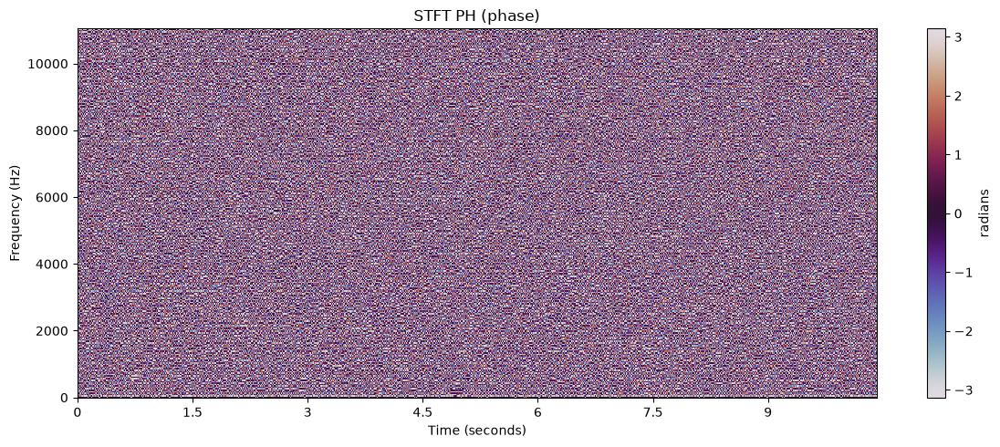

Processing outputs\white_0dB.wav...
y: [-0.0151062  -0.00653076  0.00985718 ... -0.0128479   0.02236938
  0.01986694] 

y shape: (229705,) 

sample Rate (KHz): 22050 



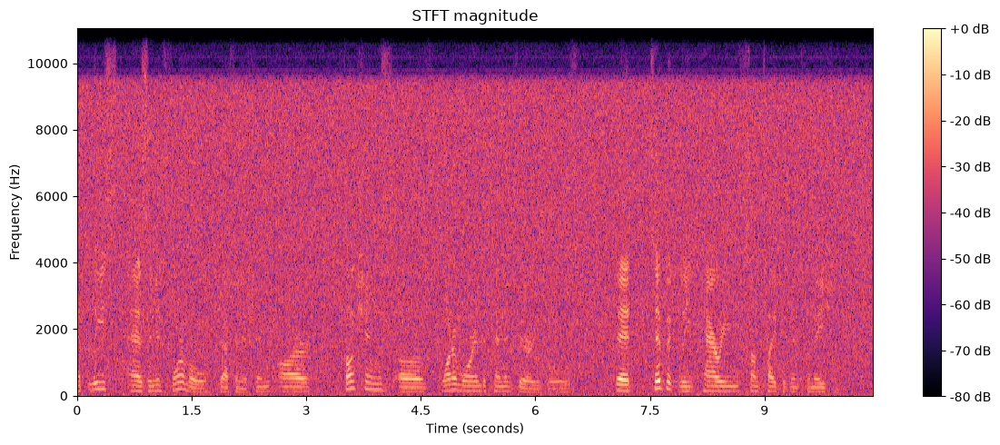

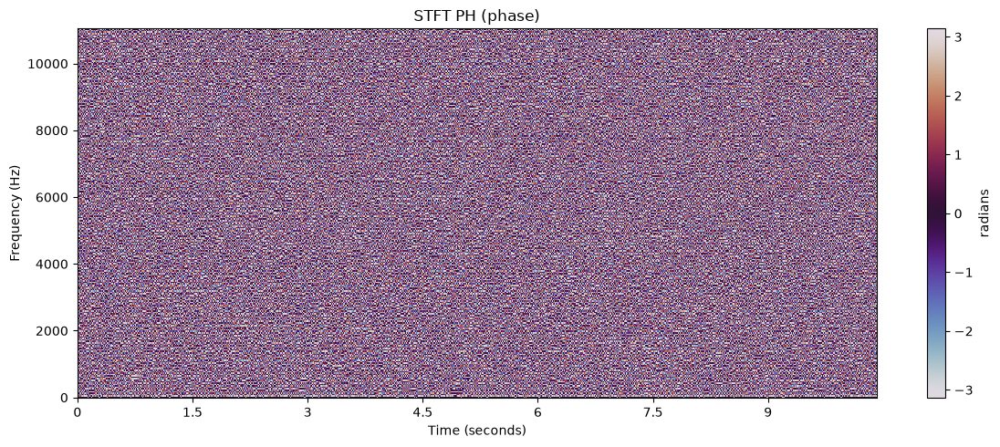

Processing outputs\white_10dB.wav...
y: [-0.00476074 -0.00210571  0.00314331 ... -0.00442505  0.0065918
  0.00598145] 

y shape: (229705,) 

sample Rate (KHz): 22050 



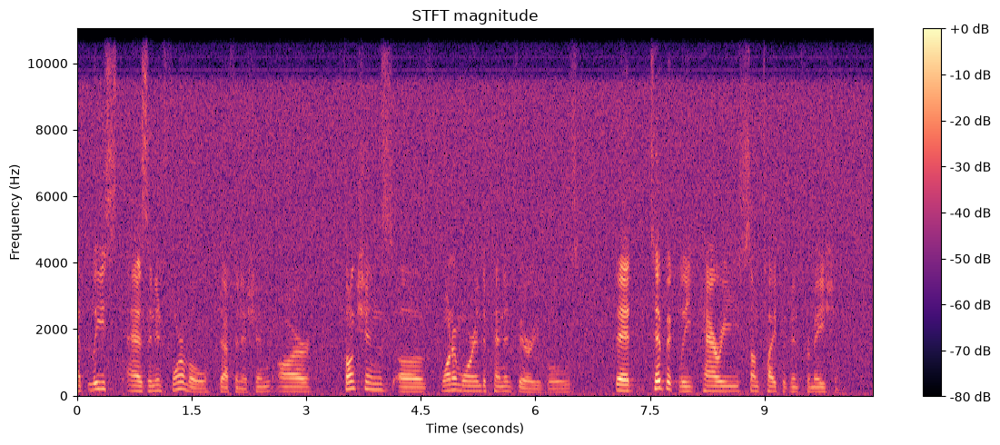

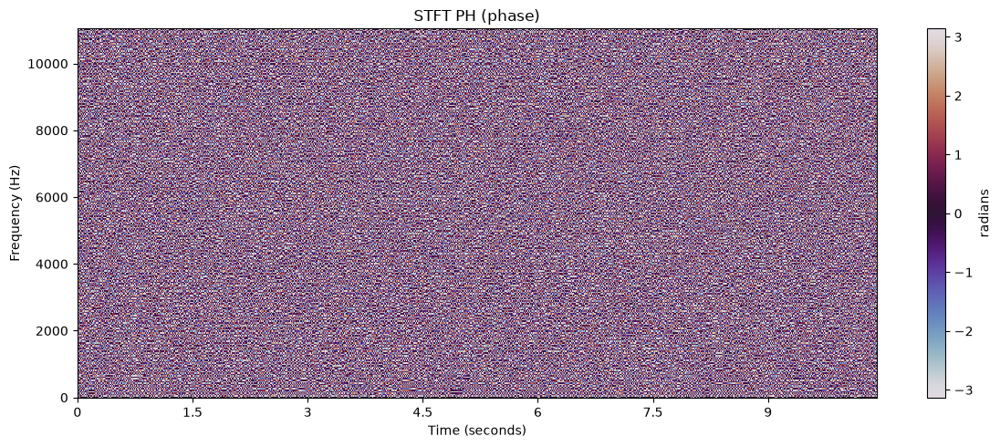

Processing outputs\white_2dB.wav...
y: [-0.01199341 -0.00521851  0.00784302 ... -0.01031494  0.01763916
  0.01571655] 

y shape: (229705,) 

sample Rate (KHz): 22050 



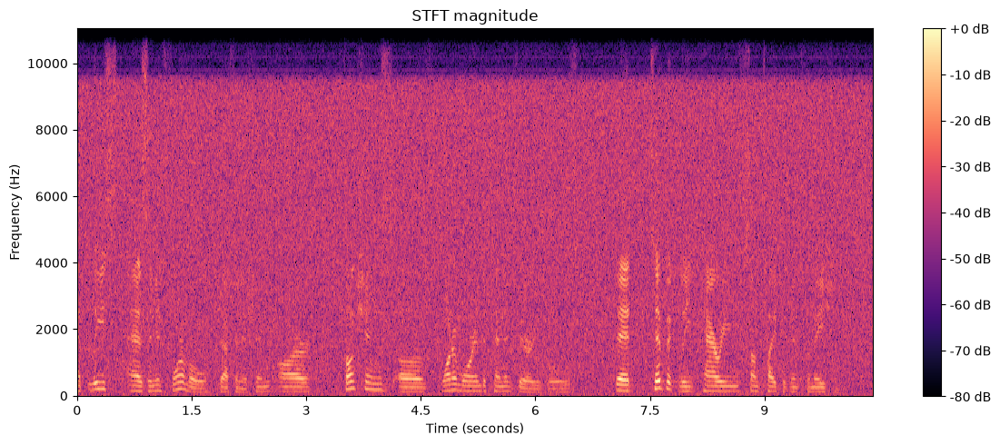

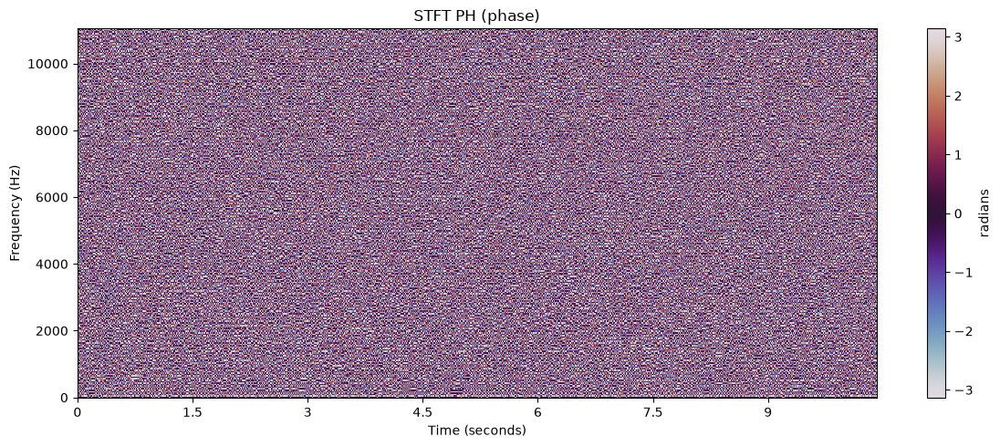

Processing outputs\white_5dB.wav...
y: [-0.00848389 -0.00369263  0.0055542  ... -0.00744629  0.01226807
  0.01098633] 

y shape: (229705,) 

sample Rate (KHz): 22050 



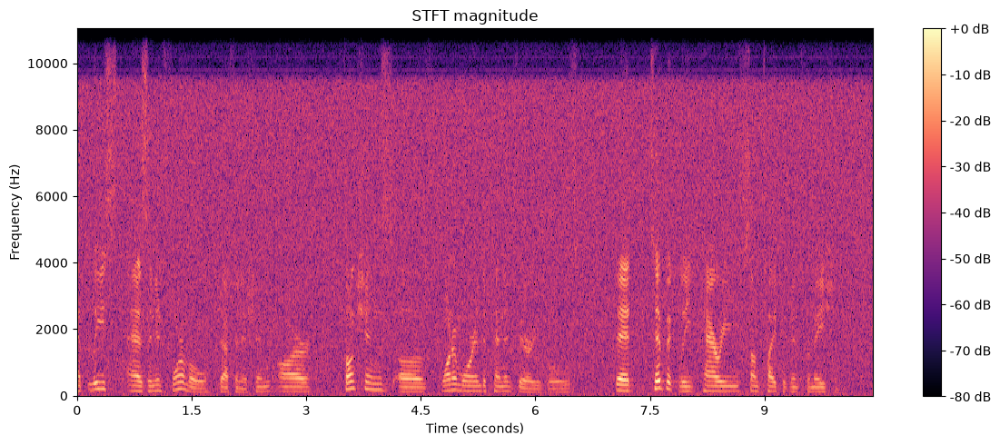

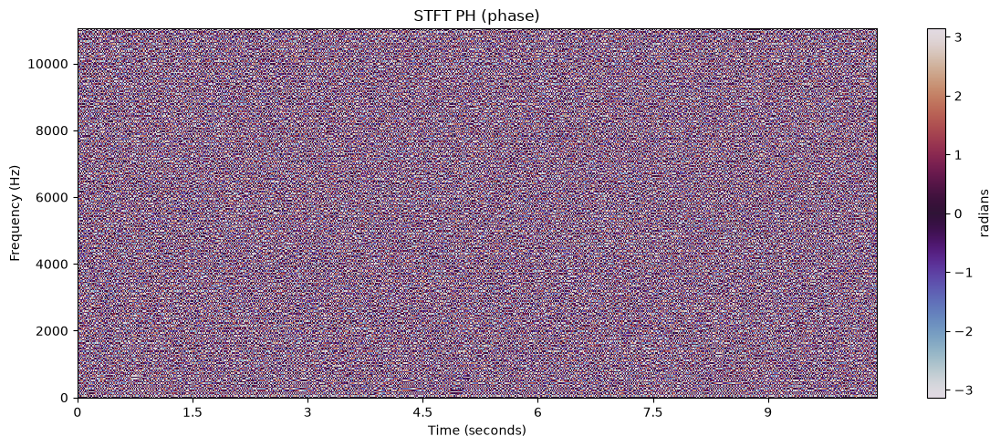

In [128]:
import glob
outputs = glob.glob("outputs/*.wav")
for audio_file in outputs:
    print(f"Processing {audio_file}...")
    fnc_2to5(audio_file)

In [94]:
def cont_fnc_2to5(audio_file):
    y,sr=librosa.load(audio_file)
    n_fft = 512
    hop_len = 128
    wind = "hann"
    D = librosa.stft(y,n_fft=n_fft,hop_length=hop_len,window=wind)
    MG = np.abs(D)
    PH = np.angle(D)
    D_MG = MG*np.exp(1j*0)
    sig1 = librosa.istft(D_MG,hop_length=hop_len,win_length=n_fft,window="hann",length=len(y))
    t_sig1 = np.arange(len(sig1))/sr
    plt.figure(figsize=(12, 4))
    plt.plot(t_sig1, sig1)
    plt.title("sig1")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.tight_layout()
    plt.show()
    PH1 = np.zeros_like(PH)
    D_sig2 = MG*np.exp(1j*PH1)
    sig2 = librosa.istft(D_sig2,hop_length=hop_len,win_length=n_fft,window="hann",length=len(y))
    t_sig2=np.arange(len(sig2))/sr
    plt.figure(figsize=(12, 4))
    plt.plot(t_sig2, sig2)
    plt.title("sig2")
    plt.xlabel("Time(sec)")
    plt.ylabel("Amplitude")
    plt.tight_layout()
    plt.show()


    

Processing outputs\babble_-2dB.wav...


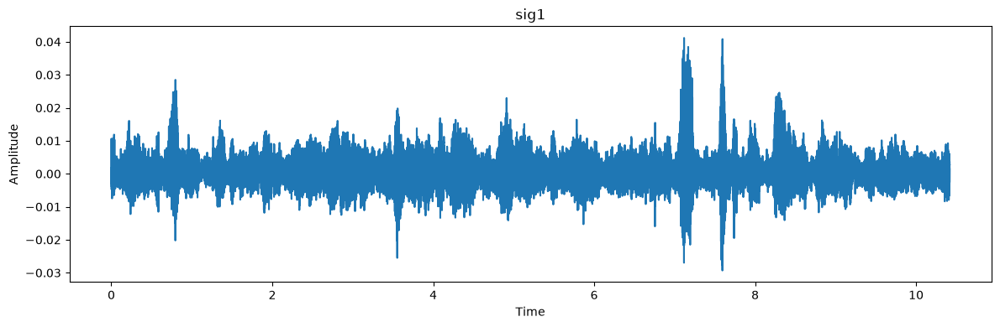

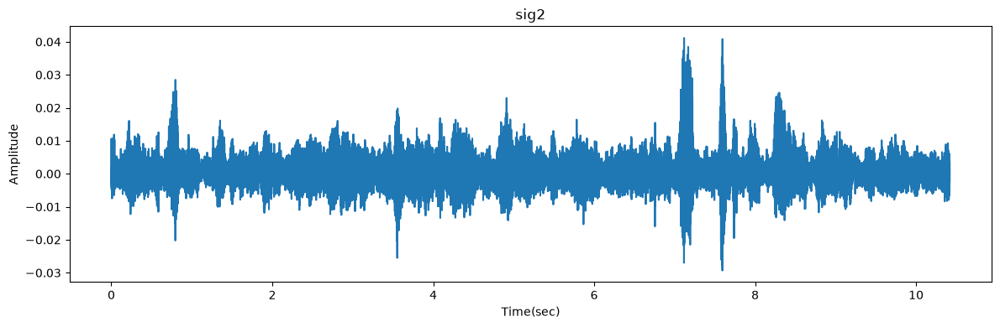

Processing outputs\babble_0dB.wav...


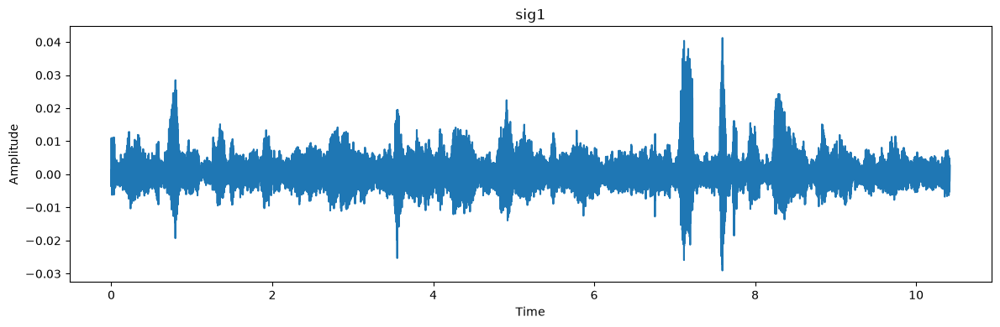

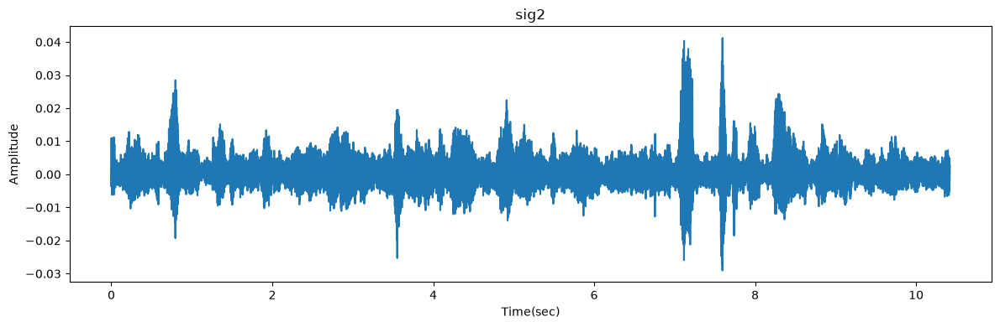

Processing outputs\babble_10dB.wav...


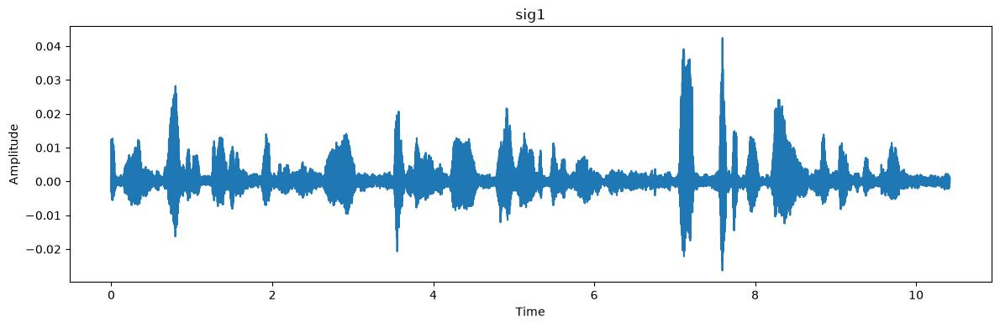

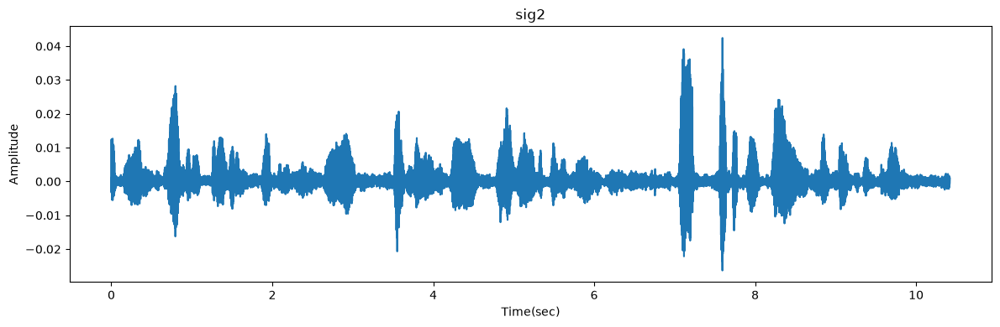

Processing outputs\babble_2dB.wav...


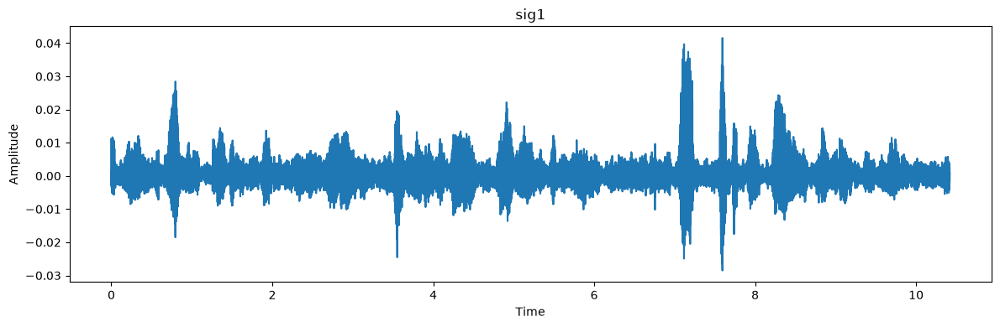

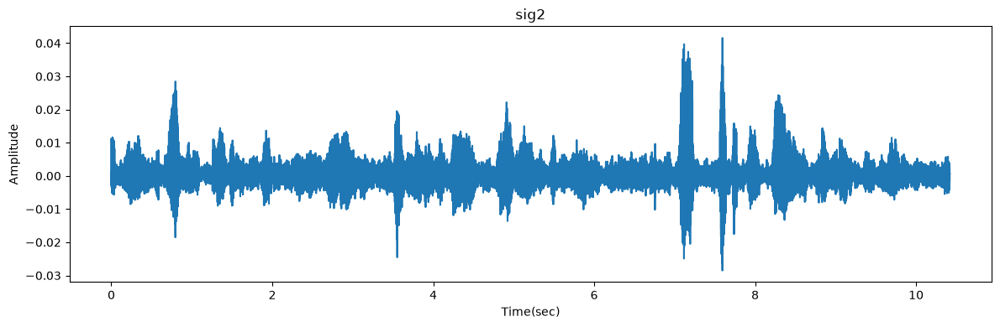

Processing outputs\babble_5dB.wav...


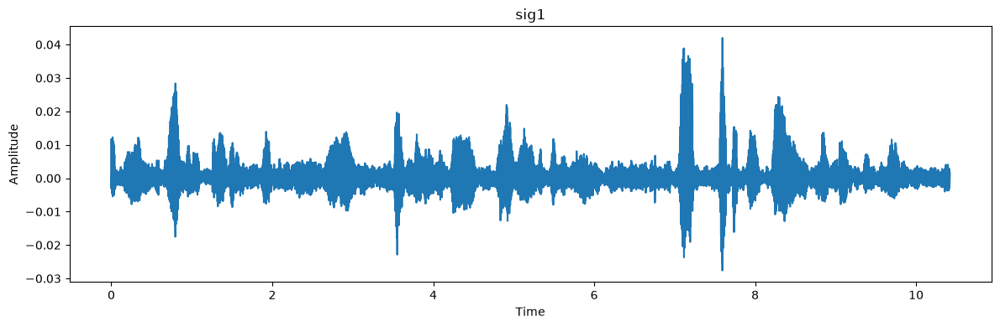

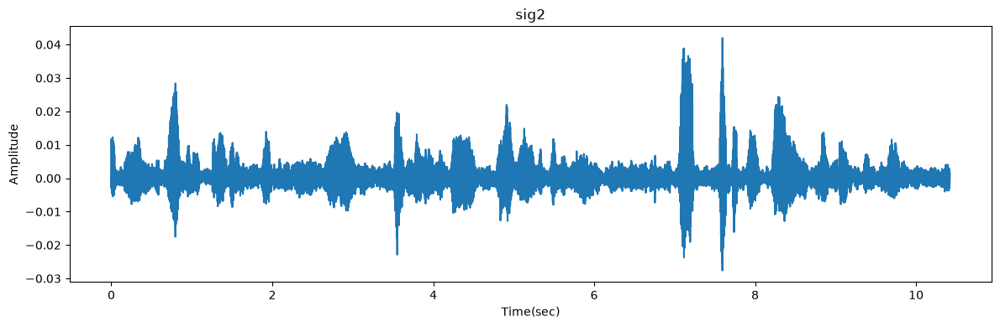

Processing outputs\machinegun_-2dB.wav...


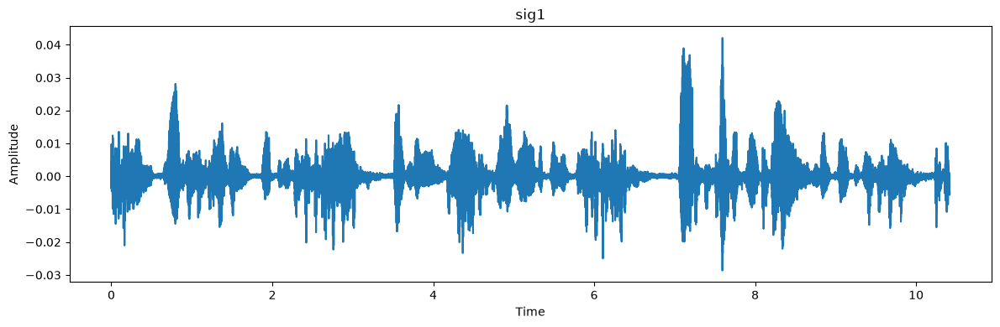

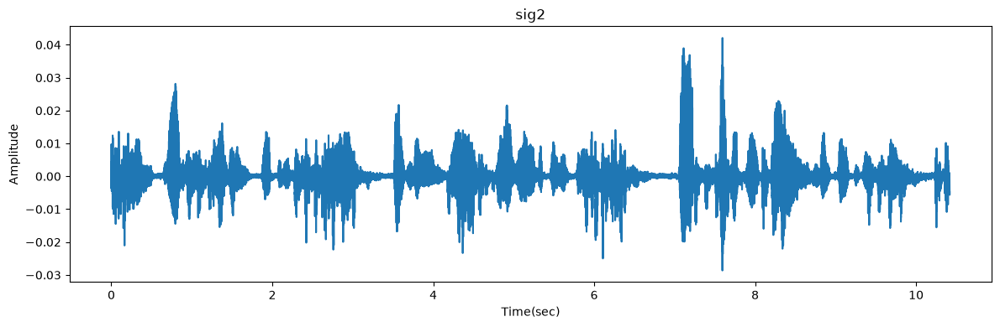

Processing outputs\machinegun_0dB.wav...


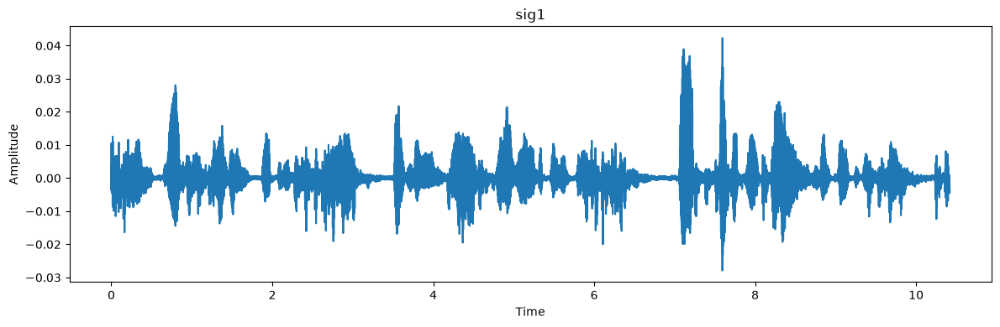

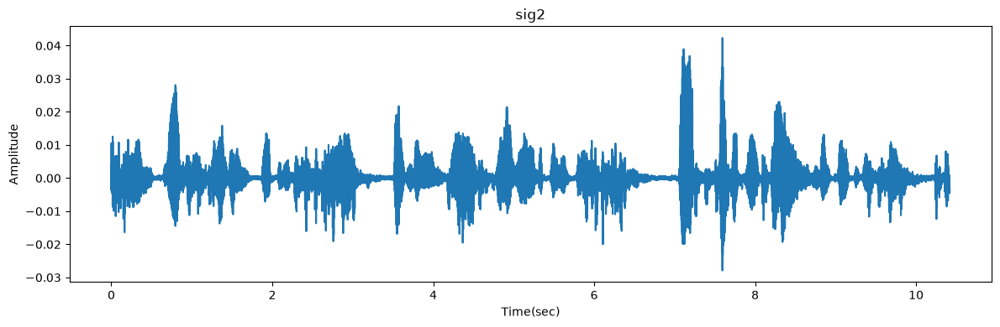

Processing outputs\machinegun_10dB.wav...


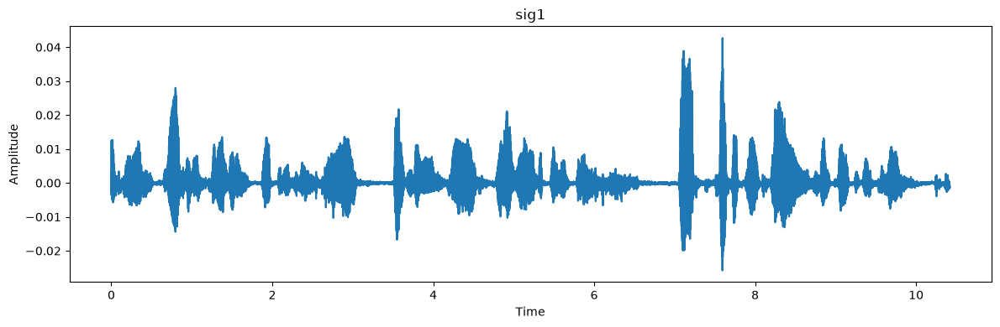

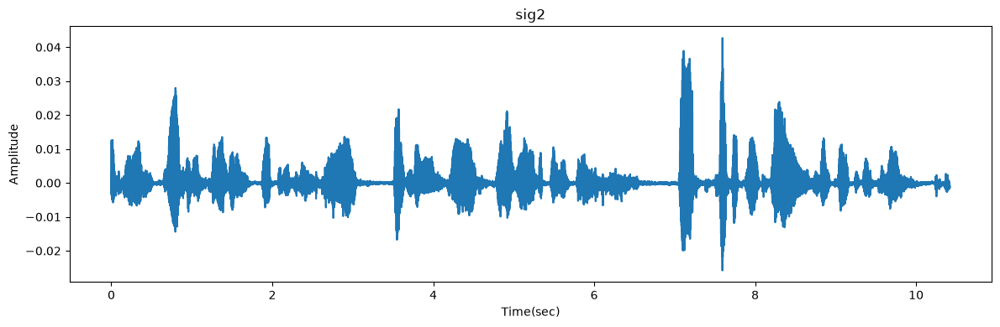

Processing outputs\machinegun_2dB.wav...


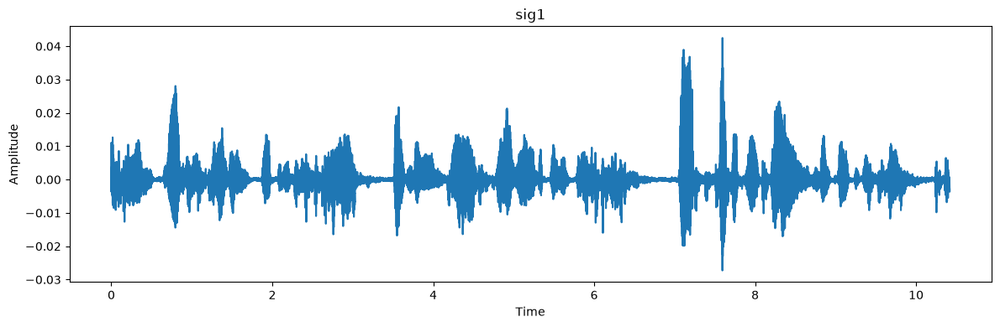

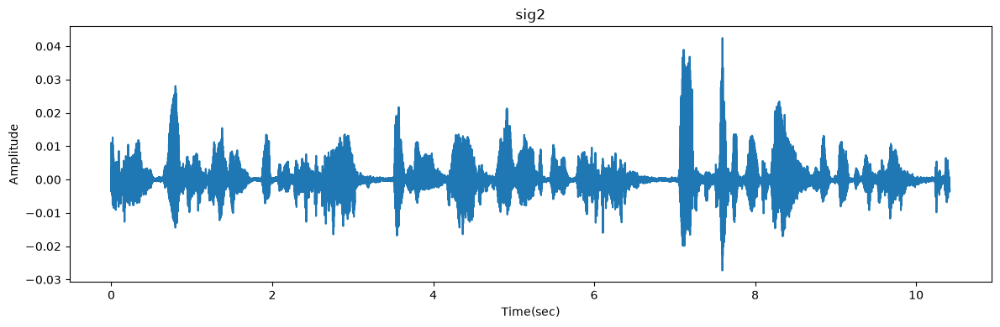

Processing outputs\machinegun_5dB.wav...


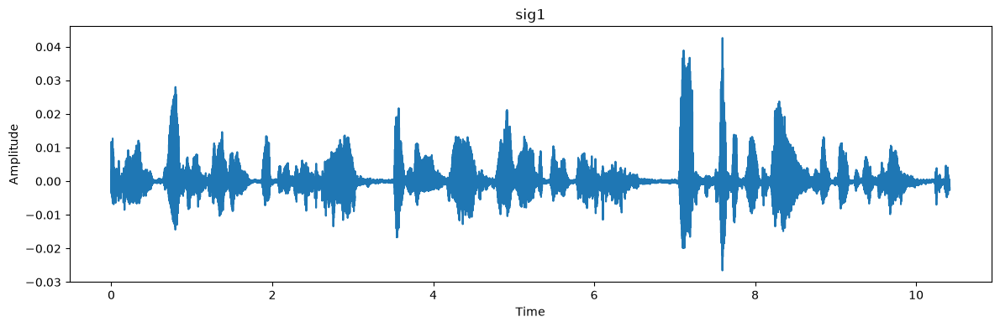

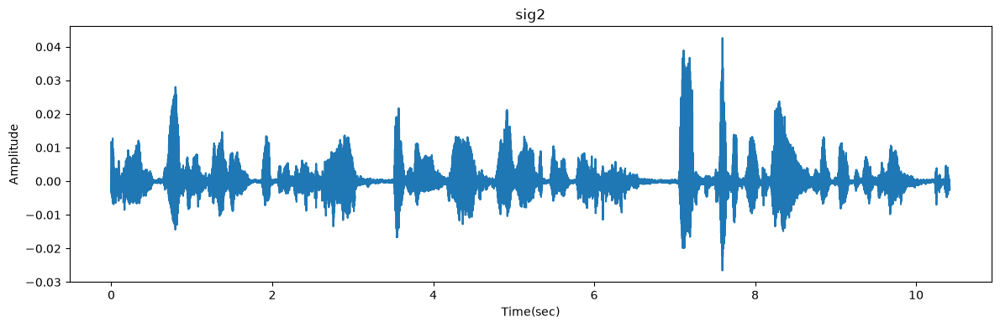

Processing outputs\white_-2dB.wav...


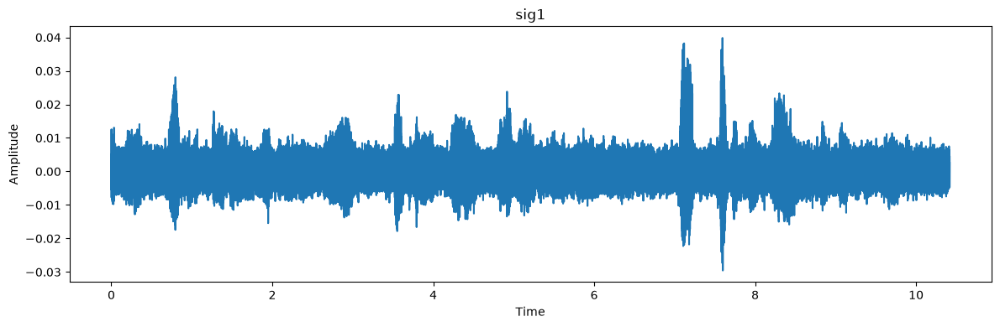

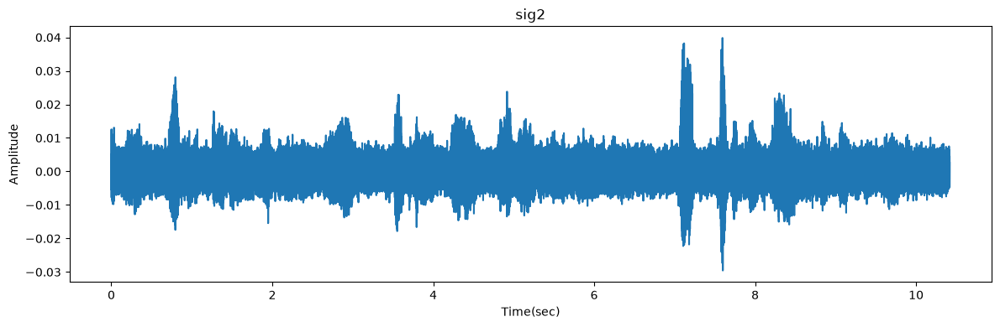

Processing outputs\white_0dB.wav...


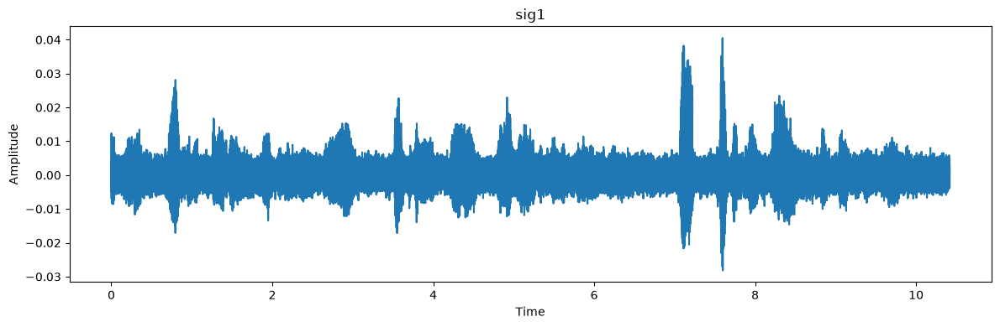

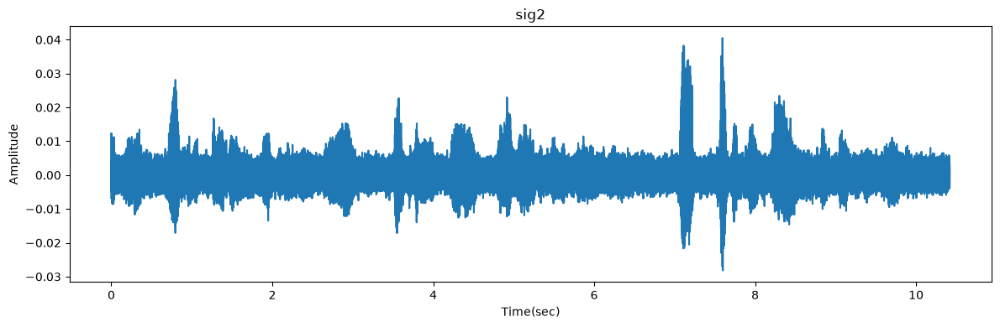

Processing outputs\white_10dB.wav...


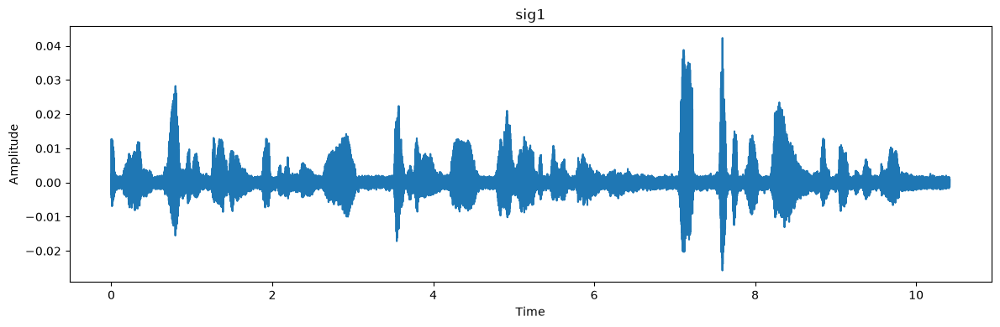

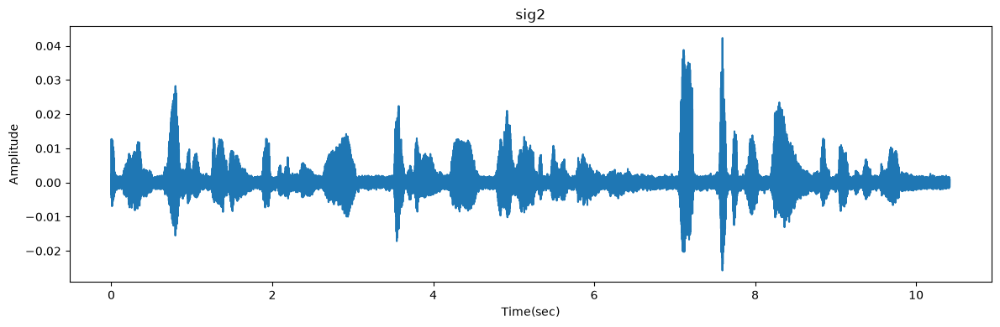

Processing outputs\white_2dB.wav...


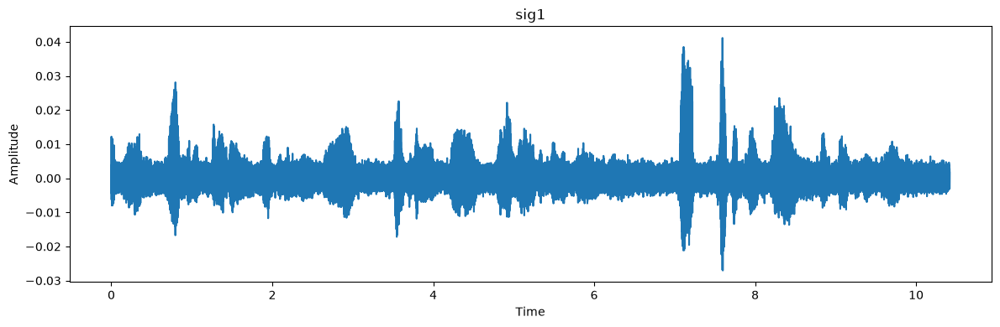

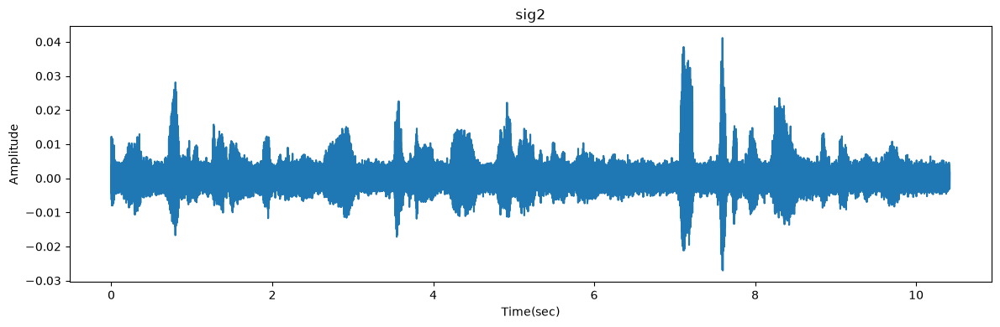

Processing outputs\white_5dB.wav...


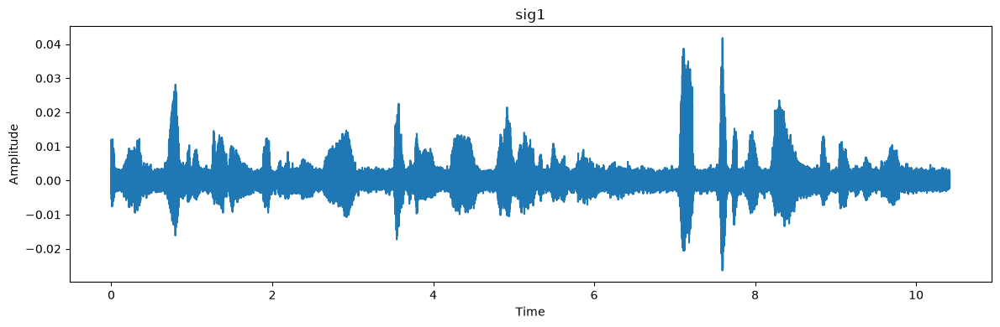

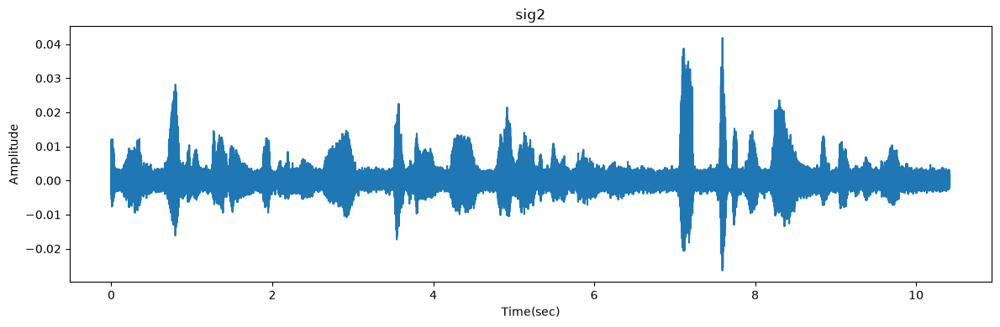

In [95]:
for audio_file in outputs:
    print(f"Processing {audio_file}...")
    cont_fnc_2to5(audio_file)

In [96]:
def fnc_noise(audio_file):
    y,sr=librosa.load(audio_file)
    n_fft = 512
    hop_len = 128
    wind = "hann"
    D = librosa.stft(y,n_fft=n_fft,hop_length=hop_len,window=wind)
    MG = np.abs(D)
    PH = np.angle(D)
    rng = np.random.default_rng(0)
    ph = randnoise(PH.shape,rng)
    D_scram =  MG * np.exp(1j * ph)
    sig_scram = librosa.istft(D_scram, hop_length=hop_len, win_length=n_fft, window="hann", length=len(y))
    sig_rec = recover(sig_scram, sr, n_fft, hop_len)
    sig_rec_oracle = recover(sig_scram, sr, n_fft, hop_len, mag=MG)
    print("STOI scrambled        :", stoi(y, sig_scram, sr))
    print("STOI recovered        :", stoi(y, sig_rec, sr))
    print("STOI recovered oracle :", stoi(y, sig_rec_oracle, sr))

In [97]:
for audio_file in outputs:
    print(f"Processing {audio_file}...")
    fnc_noise(audio_file)

Processing outputs\babble_-2dB.wav...
STOI scrambled        : 0.7144376069193702
STOI recovered        : 0.7144761217071663
STOI recovered oracle : 0.9971804813577119
Processing outputs\babble_0dB.wav...
STOI scrambled        : 0.7246241276370272
STOI recovered        : 0.7246039202658789
STOI recovered oracle : 0.9969493338586188
Processing outputs\babble_10dB.wav...
STOI scrambled        : 0.7924206915278244
STOI recovered        : 0.792489625262454
STOI recovered oracle : 0.9984448589296976
Processing outputs\babble_2dB.wav...
STOI scrambled        : 0.7366133985658502
STOI recovered        : 0.7364378706511628
STOI recovered oracle : 0.9973782179281274
Processing outputs\babble_5dB.wav...
STOI scrambled        : 0.7572200302277146
STOI recovered        : 0.7570746316254818
STOI recovered oracle : 0.9975867031710316
Processing outputs\machinegun_-2dB.wav...
STOI scrambled        : 0.8427484319058066
STOI recovered        : 0.8427781436287597
STOI recovered oracle : 0.999262348022140

# Bandpass filter

Fourth-order Butterworth, zero-phase, 100-4000 Hz

In [131]:
def apply_filter(f, signal):
    filter_type, coefficients = f

    if filter_type == "sos":
        return sosfiltfilt(coefficients, signal)

    return fftconvolve(signal, coefficients, mode="same")

In [137]:
final = make_filter("Butterworth", 100, 4000, sr)
rows = []
for (name, snr), xn in noisy_signals.items():
    noise_part = xn - y
    xf = apply_filter(final, xn)
    yf = apply_filter(final, y)
    nf = apply_filter(final, noise_part)
    rows.append({"noise": name, "snr_db": snr,
                 "STOI_noisy": stoi(y, xn, sr),
                 "STOI_filtered": stoi(y, xf, sr),
                 "delta_STOI": stoi(y, xf, sr) - stoi(y, xn, sr),
                 "SNR_gain_dB": 10 * np.log10(np.mean(yf ** 2) / np.mean(nf ** 2)) - snr})
df_final = pd.DataFrame(rows).sort_values(["noise", "snr_db"])
df_final.to_csv("bandpass_outputs/bandpass.csv", index=False)
print(df_final.round(3).to_string(index=False))

     noise  snr_db  STOI_noisy  STOI_filtered  delta_STOI  SNR_gain_dB
    babble      -2       0.579          0.578      -0.001        0.061
    babble       0       0.627          0.626      -0.001        0.061
    babble       2       0.674          0.673      -0.001        0.061
    babble       5       0.741          0.740      -0.001        0.061
    babble      10       0.837          0.835      -0.001        0.061
machinegun      -2       0.761          0.760      -0.001        1.117
machinegun       0       0.789          0.789      -0.000        1.117
machinegun       2       0.816          0.816      -0.000        1.117
machinegun       5       0.854          0.854       0.000        1.117
machinegun      10       0.909          0.908      -0.000        1.117
     white      -2       0.690          0.691       0.001        4.241
     white       0       0.732          0.733       0.001        4.241
     white       2       0.773          0.773       0.000        4.241
     w

In [ ]:
row = []
for (name, snr), xn in noisy_signals.items():
    xf = apply_filter(final, xn)
    yf = apply_filter(final, y)
    nf = apply_filter(final, xn - y)
    s_noisy = stoi(y, xn, sr)
    s_filt_orig = stoi(y, xf, sr)
    s_filt_ref = stoi(yf, xf, sr)
    row.append({"noise": name, "snr_db": snr,
                 "STOI_noisy_vs_orig": s_noisy,
                 "STOI_filt_vs_orig": s_filt_orig,
                 "delta_vs_orig": s_filt_orig - s_noisy,
                 "STOI_filt_vs_filtclean": s_filt_ref,
                 "SNR_gain_dB": 10 * np.log10(np.mean(yf ** 2) / np.mean(nf ** 2)) - snr})

df_final1 = pd.DataFrame(row).sort_values(["noise", "snr_db"])
print(df_final1.round(4).to_string(index=False))

     noise  snr_db  STOI_noisy_vs_orig  STOI_filt_vs_orig  delta_vs_orig  STOI_filt_vs_filtclean  SNR_gain_dB
    babble      -2              0.5793             0.5780        -0.0013                  0.6146       0.0606
    babble       0              0.6268             0.6255        -0.0012                  0.6664       0.0606
    babble       2              0.6738             0.6727        -0.0011                  0.7169       0.0606
    babble       5              0.7412             0.7401        -0.0011                  0.7876       0.0606
    babble      10              0.8368             0.8354        -0.0014                  0.8817       0.0606
machinegun      -2              0.7607             0.7601        -0.0006                  0.7809       1.1174
machinegun       0              0.7892             0.7890        -0.0003                  0.8092       1.1174
machinegun       2              0.8162             0.8162        -0.0000                  0.8353       1.1174
machinegun